# 03 — Seleção e transformação das variáveis

**Enunciado etapa 3** \
Seleção e transformação das variáveis: defina a codificação das variáveis
categóricas e a necessidade de padronização das variáveis numéricas. Investigue
possíveis redundâncias e avalie se a seleção ou criação de variáveis contribui para
os resultados.

Todas as decisões deste notebook são tomadas **apenas com o treino** (`train.csv`)

**Observação**:
Para o teste dos modelos, será feito um pipeline de testes de performance de cada conjunto de variáveis. Inicialmente testarei o conjunto de todas as variáveis iniciais. Esse notebook é para realizar a Seleção de variáveis e Engenharia de atributos, etapas que serão parte do pipeline.

**Saídas deste notebook**:
- `data/processed/feature_set.json` — conjunto de variáveis escolhido
- `data/processed/train_fe.csv` e `test_fe.csv` — treino e teste com as variáveis criadas (regras fixas, sem nenhum parâmetro estimado)

In [1]:
# Imports
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

In [2]:
# Leitura do treino
train = pd.read_csv("../data/processed/train.csv")
TARGET = "Churn"
X = train.drop(columns=["customerID", TARGET])
y = train[TARGET]
print(X.shape, f"taxa de churn no treino = {y.mean():.1%}")
X.head()

(5634, 19) taxa de churn no treino = 26.5%


,is_male,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,1,0,0,0,35,0,0,DSL,0,0,1,0,1,1,Month-to-month,0,Electronic check,49.20,1701.65
1,1,0,1,1,15,1,0,Fiber optic,1,0,0,0,0,0,Month-to-month,0,Mailed check,75.10,1151.55
2,1,0,1,1,13,0,0,DSL,1,1,0,1,0,0,Two year,0,Mailed check,40.55,590.35
3,0,0,1,0,26,1,0,DSL,0,1,1,0,1,1,Two year,1,Credit card (automatic),73.50,1905.70
4,1,0,1,1,1,1,0,DSL,0,0,0,0,0,0,Month-to-month,0,Electronic check,44.55,44.55


Separação das colunas em grupos, de acordo com o tratamento feito no notebook 01

In [3]:
# Grupos de colunas
NUMERICAS = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAS = ["InternetService", "Contract", "PaymentMethod"]
BINARIAS = [c for c in X.columns if c not in NUMERICAS + CATEGORICAS]
SERVICOS_ADICIONAIS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                       "TechSupport", "StreamingTV", "StreamingMovies"]
print("Numéricas: ", NUMERICAS)
print("Categóricas:", CATEGORICAS)
print("Binárias:  ", BINARIAS)

Numéricas:  ['tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas: ['InternetService', 'Contract', 'PaymentMethod']
Binárias:   ['is_male', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']


## 1. Codificação das variáveis categóricas

- As **13 variáveis binárias** já foram convertidas para 0/1 no notebook 01 (incluindo os serviços de internet e `MultipleLines`, depois de juntar "No internet service"/"No phone service" com "No"). Não precisam de mais nenhuma transformação.
- Restam as variáveis `InternetService`, `Contract` e `PaymentMethod`, que possuem mais de duas categorias. Por isso uso **one-hot encoding** nelas

In [4]:
for col in CATEGORICAS:
    print(X[col].value_counts().to_string(), "\n")

InternetService
Fiber optic    2483
DSL            1937
No             1214 

Contract
Month-to-month    3102
Two year          1359
One year          1173 

PaymentMethod
Electronic check             1891
Mailed check                 1286
Bank transfer (automatic)    1244
Credit card (automatic)      1213 



Usarei `drop="first"` para evitar problema de colinearidade nos coeficientes da Regressão Logística

In [5]:
def fazer_preprocessador(numericas, binarias, categoricas, escalar=True):
    # One-hot nas categóricas, padronização opcional nas numéricas e binárias sem alteração
    return ColumnTransformer([
        ("num", StandardScaler() if escalar else "passthrough", numericas),
        ("bin", "passthrough", binarias),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categoricas),
    ], verbose_feature_names_out=False)


# Base codificada (sem padronização) só para inspecionar as colunas
prep = fazer_preprocessador(NUMERICAS, BINARIAS, CATEGORICAS, escalar=False).set_output(transform="pandas")
X_enc = prep.fit_transform(X)
print(f"{X.shape[1]} variáveis originais -> {X_enc.shape[1]} colunas após a codificação")
print([c for c in X_enc.columns if c.startswith(tuple(CATEGORICAS))])

19 variáveis originais -> 23 colunas após a codificação
['InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


Categorias de referência (removidas): `InternetService = DSL`, `Contract = Month-to-month` e `PaymentMethod = Bank transfer (automatic)`.

## 2. Padronização das variáveis numéricas

In [6]:
X[NUMERICAS].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,32.49,64.93,2299.33
std,24.57,30.14,2279.20
min,0.00,18.40,0.00
25%,9.00,35.66,402.98
50%,29.00,70.50,1394.92
75%,55.00,90.00,3835.82
max,72.00,118.75,8684.80


As três numéricas têm escalas muito diferentes: `tenure` vai de 0 a 72, `MonthlyCharges` de ~18 a ~119 e `TotalCharges` de 0 a ~8.700, enquanto as binárias e dummies valem 0 ou 1.

- O k-NN usa distâncias. Por isso, variáveis com escala maior podem dominar o cálculo da distância. Na escala atual das variáveis, `TotalCharges` terá uma influência muito maior na distância euclidiana apenas porque está em uma escala maior.
- Regressão logística é também sensível à **escala** das variáveis: como o modelo é ajustado via otimização numérica e regularizado (penalizando o tamanho dos coeficientes), variáveis em escalas muito diferentes podem distorcer o processo de otimização e a regularização
- **Árvores** (árvore de decisão, Random Forest, Gradient Boosting) fazem cortes do tipo `x <= c`, que não mudam com transformações monótonas. Para elas, padronizar é indiferente.

Por isso, para evitar esse problema no KNN e na Regressão, usaremos **padronização** com `StandardScaler`, ajustado só no treino de cada fold, transformando cada variável para ter média 0 e desvio padrão 1:
$$
z = \frac{x - \mu}{\sigma}.
$$

Abaixo, verifico o efeito na prática com validação cruzada: o mesmo modelo com e sem padronização, nos mesmos 5 folds.

**[IA] - Tive o auxílio de IA para fazer as funções reutilizáveis abaixo, tornando o código mais limpo, e deixando os testes mais práticos de serem realizados**

In [7]:
# Protocolo de avaliação usado em todo o notebook (os mesmos 5 folds para todos os modelos)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
METRICAS = {"roc_auc": "roc_auc", "ap": "average_precision", "f1": "f1"}


def avaliar(modelo, X, y):
    # Métricas de cada fold da validação cruzada
    r = cross_validate(modelo, X, y, cv=CV, scoring=METRICAS, n_jobs=-1)
    return pd.DataFrame({m: r[f"test_{m}"] for m in METRICAS})


def resumir(resultados):
    # Média ± desvio padrão entre os folds
    g = resultados.groupby(["modelo", "configuração"])[list(METRICAS)]
    media, desvio = g.mean(), g.std()
    return media.round(3).astype(str) + " ± " + desvio.round(3).astype(str)

In [8]:
linhas = []
for nome, modelo in [("LogReg", LogisticRegression(max_iter=5000)), ("KNN", KNeighborsClassifier(n_neighbors=25))]:
    for escalar in [False, True]: # Testar com o sem StandardScaler -> True para com, False para sem
        pipe = Pipeline([("prep", fazer_preprocessador(NUMERICAS, BINARIAS, CATEGORICAS, escalar)),
                         ("modelo", modelo)])
        res = avaliar(pipe, X, y).assign(modelo=nome, configuração="padronizado" if escalar else "sem padronizar") # True para padronizado, False para sem padronizar
        linhas.append(res)
res_escala = pd.concat(linhas)
resumir(res_escala)

roc_auc             ap             f1
modelo configuração                                               
KNN    padronizado     0.834 ± 0.011   0.62 ± 0.013  0.597 ± 0.019
       sem padronizar   0.78 ± 0.011  0.579 ± 0.027  0.477 ± 0.038
LogReg padronizado     0.846 ± 0.014  0.661 ± 0.022  0.593 ± 0.034
       sem padronizar  0.846 ± 0.014  0.662 ± 0.021  0.593 ± 0.034

- Para o **KNN**, a padronização faz muita diferença. A AP sobe de 0,579 para 0,620, a ROC-AUC de 0,780 para 0,834 e o F1 de 0,477 para 0,597
- Para a **Regressão logística**, o resultado é praticamente idêntico. Mesmo assim, decido manter a padronização, pois ela ajuda na convergência e deixa os coeficientes comparáveis entre si

Portanto, seguirei usando o `StandardScaler` nas numéricas para todos os modelos

## 3. Redundâncias

### 3.1 Correlação entre as variáveis

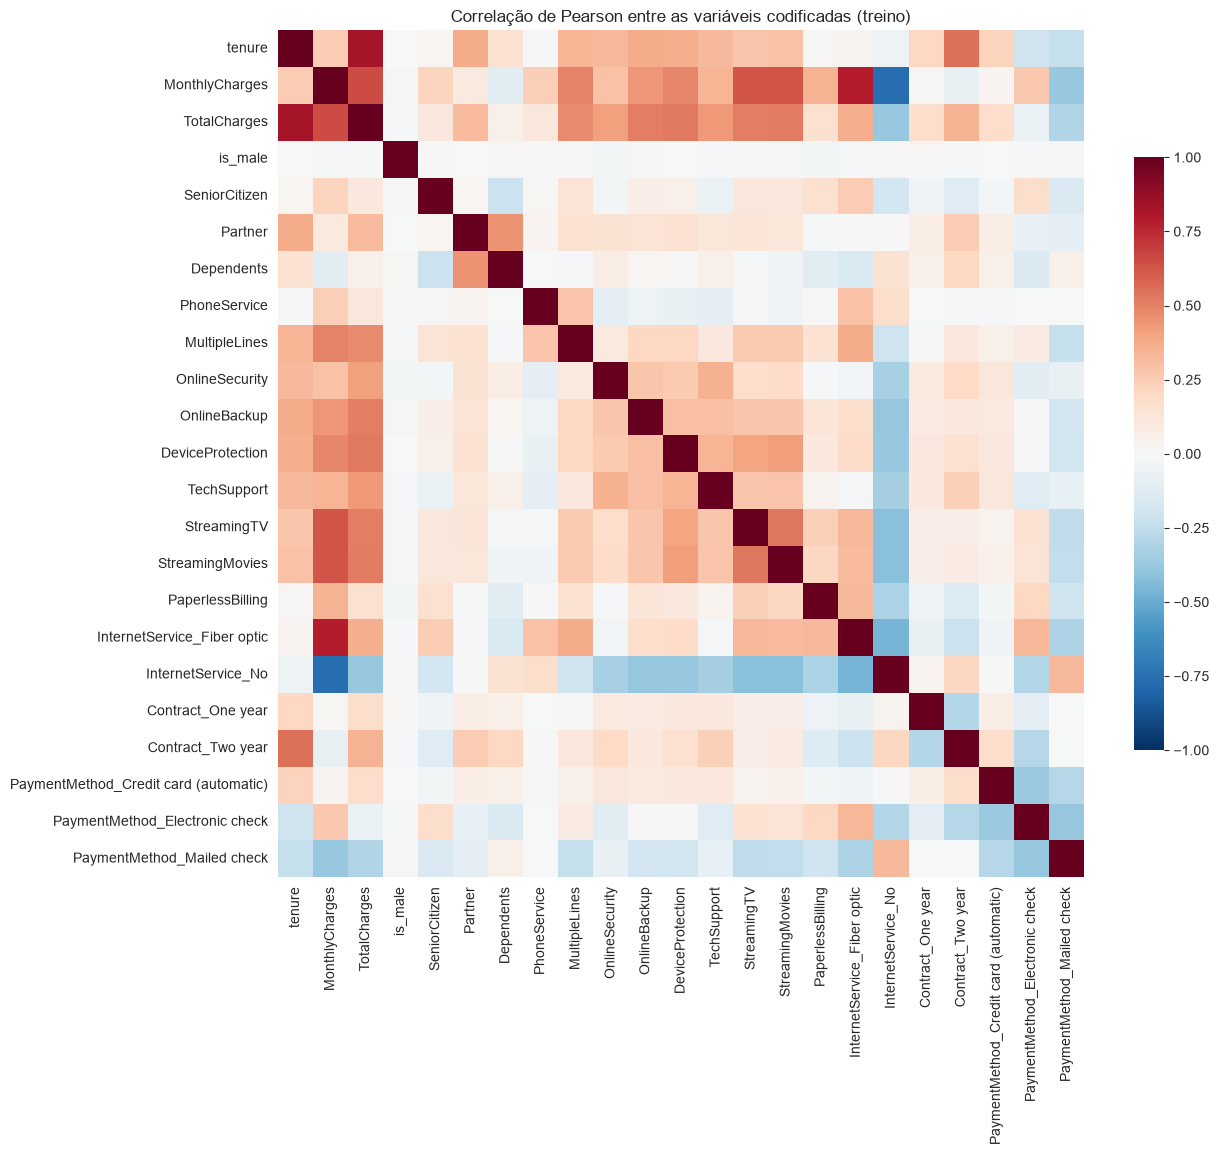

In [9]:
corr = X_enc.corr()
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Correlação de Pearson entre as variáveis codificadas (treino)")
plt.show()

In [10]:
# Pares mais correlacionados
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pares = pares.reindex(pares.abs().sort_values(ascending=False).index)
pares[pares.abs() >= 0.5].round(3).to_frame("correlação")

correlação
tenure         TotalCharges                      0.830
MonthlyCharges InternetService_Fiber optic       0.788
               InternetService_No               -0.762
               TotalCharges                      0.654
               StreamingTV                       0.632
               StreamingMovies                   0.625
tenure         Contract_Two year                 0.555
StreamingTV    StreamingMovies                   0.536
TotalCharges   DeviceProtection                  0.528
               StreamingMovies                   0.520
               OnlineBackup                      0.514
               StreamingTV                       0.513

- `tenure` × `TotalCharges` (0,83) - já era esperado, já que `TotalCharges ≈ tenure × MonthlyCharges` (notebook 01)
- `MonthlyCharges` × tipo de internet (0,79 com fibra, −0,76 sem internet) e × streaming (~0,63) - também esperado, pois a mensalidade depende diretamente dos serviços contratados
- `tenure` × `Contract_Two year` (0,56) - clientes com contrato bianual tendem a estar há mais tempo na empresa

### 3.2 Multicolinearidade (VIF)

O VIF (*Variance Inflation Factor*) mede o quanto cada variável é explicada por **todas as outras juntas**: $VIF_j = 1 / (1 - R^2_j)$, onde $R^2_j$ vem da regressão da variável $j$ nas demais. Valores acima de 10 costumam indicar multicolinearidade forte.

In [11]:
def calcular_vif(df):
    # VIF_j é o j-ésimo elemento da diagonal da inversa da matriz de correlação
    return pd.Series(np.diag(np.linalg.inv(df.corr().values)), index=df.columns).sort_values(ascending=False)

calcular_vif(X_enc).round(1).head(12).to_frame("VIF")

,VIF
MonthlyCharges,861.9
InternetService_Fiber optic,147.8
InternetService_No,103.1
PhoneService,35.3
StreamingTV,24.0
StreamingMovies,24.0
TotalCharges,11.0
tenure,7.6
MultipleLines,7.3
DeviceProtection,6.9


`MonthlyCharges` tem VIF muito alto. A teoria é que a mensalidade seja quase uma soma dos preços dos serviços contratados. Verifico isso com uma regressão linear de `MonthlyCharges` nos serviços:

In [12]:
servicos = ["PhoneService", "MultipleLines", *SERVICOS_ADICIONAIS,
            *[c for c in X_enc.columns if c.startswith("InternetService")]]
reg = LinearRegression().fit(X_enc[servicos], X_enc["MonthlyCharges"])
print(f"R² de MonthlyCharges explicada pelos serviços: {reg.score(X_enc[servicos], X_enc['MonthlyCharges']):.4f}")
pd.Series(reg.coef_, index=servicos).round(2).to_frame("preço estimado (US$)")

R² de MonthlyCharges explicada pelos serviços: 0.9988


,preço estimado (US$)
PhoneService,20.03
MultipleLines,5.01
OnlineSecurity,5.04
OnlineBackup,4.96
DeviceProtection,5.03
TechSupport,5.05
StreamingTV,9.96
StreamingMovies,9.95
InternetService_Fiber optic,24.98
InternetService_No,-25.04


In [13]:
# VIF sem MonthlyCharges e sem TotalCharges
calcular_vif(X_enc.drop(columns=["MonthlyCharges", "TotalCharges"])).round(1).head(6).to_frame("VIF")

,VIF
tenure,2.8
InternetService_No,2.7
Contract_Two year,2.6
InternetService_Fiber optic,2.0
PaymentMethod_Electronic check,2.0
PaymentMethod_Mailed check,1.8


- `MonthlyCharges` é realmente explicada pelos serviços com **R² = 0,999**. Os coeficientes são "preços de tabela" redondos (telefone ≈ US 20, fibra ≈ US 25 a mais que DSL, cada serviço adicional ≈ US 5, cada streaming ≈ US 10). Ou seja, `MonthlyCharges` é quase uma combinação linear das variáveis de serviço, por isso o VIF de ~860
- `TotalCharges` (VIF 11) é redundante com `tenure` e `MonthlyCharges`, como esperado
- Sem essas duas variáveis, todos os VIFs ficam abaixo de 3, ou seja, as demais variáveis não têm multicolinearidade relevante.

**Consequências:**
- Para os **modelos de árvore** e para o **KNN**, a redundância não é um problema grave para a previsão.
- Para a **regressão logística**, a multicolinearidade não piora muito a previsão, mas deixa os coeficientes instáveis e difíceis de interpretar (o efeito de `MonthlyCharges` se confunde com o dos serviços)
- `TotalCharges` é a candidata natural a ser removida, porque sua informação já está em `tenure` × `MonthlyCharges`
- Mantenho `MonthlyCharges`, apesar dela ser redundante com os serviços em conjunto, ela resume o "tamanho" do pacote do cliente, o que é útil para modelos como o KNN

### 3.3 Relevância individual de cada variável

Para ter uma ideia de quais variáveis carregam pouca informação sobre o churn, calculo a **informação mútua** de cada coluna com o `Churn` (mede dependência de qualquer tipo, não só linear) e a correlação com o `Churn`.

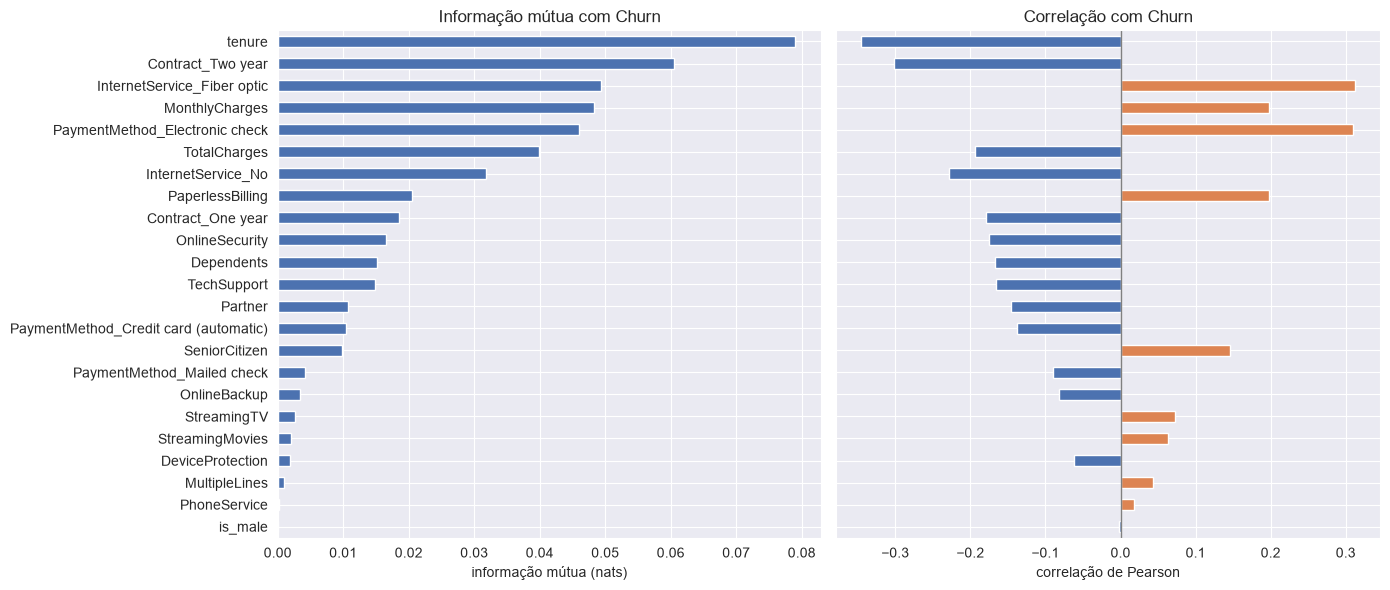

,info_mutua,corr_churn
StreamingTV,0.0026,0.0724
StreamingMovies,0.0020,0.0638
DeviceProtection,0.0019,-0.0616
MultipleLines,0.0010,0.0438
PhoneService,0.0002,0.0179
is_male,0.0000,-0.0022


In [14]:
discretas = [c not in NUMERICAS for c in X_enc.columns]
relevancia = pd.DataFrame({
    "info_mutua": mutual_info_classif(X_enc, y, discrete_features=discretas, random_state=42),
    "corr_churn": X_enc.corrwith(y),
}, index=X_enc.columns).sort_values("info_mutua", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
relevancia["info_mutua"].plot.barh(ax=axes[0], color="#4C72B0")
relevancia["corr_churn"].plot.barh(ax=axes[1], color=np.where(relevancia["corr_churn"] > 0, "#DD8452", "#4C72B0"))
axes[0].set(title="Informação mútua com Churn", xlabel="informação mútua (nats)")
axes[1].set(title="Correlação com Churn", xlabel="correlação de Pearson")
axes[1].axvline(0, color="gray", lw=1)
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()
relevancia.round(4).tail(6)

- As variáveis mais informativas são as mesmas que se destacaram na EDA: contrato, `tenure`, tipo de internet, `TotalCharges`/`MonthlyCharges`, forma de pagamento, `OnlineSecurity` e `TechSupport`.
- `is_male` e `PhoneService` têm informação mútua praticamente nula e correlação com o churn próxima de 0 (como na EDA). `PhoneService` ainda é redundante com `MultipleLines` (só tem várias linhas quem tem telefone) e com `MonthlyCharges`.
- Streaming, `DeviceProtection` e `MultipleLines` também têm pouca informação **individual**, mas podem ser úteis combinadas com as demais (por exemplo, dentro do total de serviços contratados).

### 3.4 Weight of Evidence (WoE) e Information Value (IV)

O WoE e o IV são medidas clássicas de *credit scoring* para alvos binários. Para cada categoria (ou faixa, no caso das numéricas) de uma variável:

$$WoE = \ln\left(\frac{\%\ \text{dos churns que estão na categoria}}{\%\ \text{dos não churns que estão na categoria}}\right) \qquad IV = \sum_{\text{categorias}} (\%\ \text{churns} - \%\ \text{não churns}) \times WoE$$

- **WoE > 0**: a categoria concentra proporcionalmente mais churns que não churns (risco acima da média); **WoE < 0**: risco abaixo da média. Em crédito, costuma-se usar a razão invertida (bons/maus); aqui uso churn no numerador para que WoE positivo signifique mais churn.
- O **IV** resume o quanto as distribuições de churn e não churn diferem entre as categorias, ou seja, o poder de separação da variável **sozinha**. A vantagem em relação à correlação é que ele mede a variável inteira (ex.: `Contract` com suas 3 categorias, não cada dummy) e capta relações não lineares.
- Escala usual: IV < 0,02 inútil; 0,02–0,1 fraco; 0,1–0,3 médio; 0,3–0,5 forte; > 0,5 muito forte (em crédito, costuma ser sinal de vazamento a investigar).

As numéricas com muitos valores são discretizadas em decis. Uso uma suavização de 0,5 nas contagens para evitar $\ln(0)$ em categorias sem churn ou sem não churn. Os serviços são avaliados na forma binária usada pelos modelos (após juntar "No internet service" com "No"). O IV é calculado no treino inteiro e usado só para **orientar** a escolha de um conjunto fixo de variáveis.

In [15]:
def tabela_woe(x, y, suavizacao=0.5):
    # n, taxa de churn, WoE e contribuição para o IV de cada categoria de x
    tab = pd.crosstab(x, y).reindex(columns=[0, 1], fill_value=0)
    tab.columns = ["nao_churn", "churn"]
    dist_churn = (tab["churn"] + suavizacao) / (tab["churn"] + suavizacao).sum()
    dist_nao = (tab["nao_churn"] + suavizacao) / (tab["nao_churn"] + suavizacao).sum()
    tab["n"] = tab["churn"] + tab["nao_churn"]
    tab["taxa_churn"] = tab["churn"] / tab["n"]
    tab["woe"] = np.log(dist_churn / dist_nao)
    tab["iv"] = (dist_churn - dist_nao) * tab["woe"]
    return tab[["n", "taxa_churn", "woe", "iv"]]


def discretizar(s, n_faixas=10):
    # Numéricas com muitos valores viram decis; as demais ficam como estão
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > n_faixas:
        return pd.qcut(s, n_faixas, duplicates="drop", precision=1)
    return s


def calcular_iv(df, y):
    return pd.Series({col: tabela_woe(discretizar(df[col]), y)["iv"].sum() for col in df.columns}).sort_values(ascending=False)


FAIXAS_IV = [0, 0.02, 0.1, 0.3, 0.5, np.inf]
ROTULOS_IV = ["inútil", "fraco", "médio", "forte", "muito forte"]

iv = calcular_iv(X, y)
tabela_iv = pd.DataFrame({"IV": iv.round(4), "poder preditivo": pd.cut(iv, FAIXAS_IV, labels=ROTULOS_IV, right=False)})
tabela_iv

,IV,poder preditivo
Contract,1.2357,muito forte
tenure,0.7802,muito forte
InternetService,0.6328,muito forte
PaymentMethod,0.4806,forte
MonthlyCharges,0.3631,forte
TotalCharges,0.3039,forte
PaperlessBilling,0.2167,médio
OnlineSecurity,0.1788,médio
Dependents,0.1620,médio
TechSupport,0.1590,médio


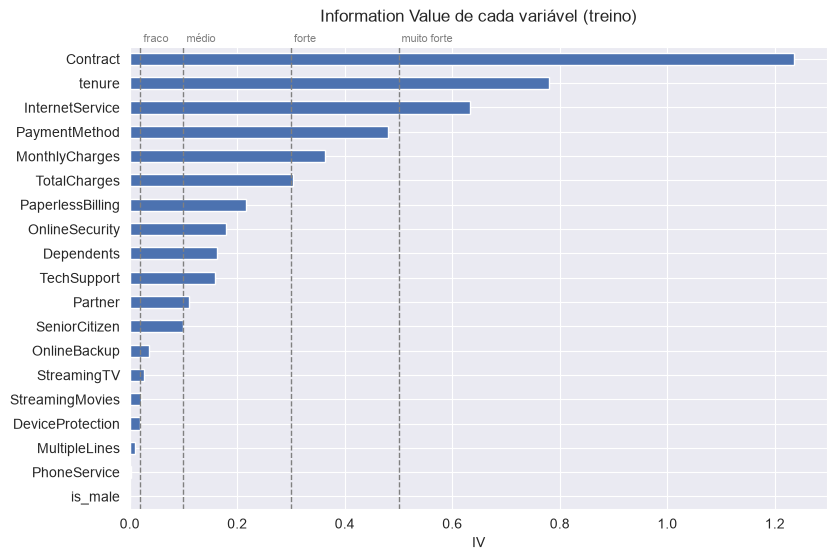

In [16]:
fig, ax = plt.subplots(figsize=(9, 6))
iv.plot.barh(ax=ax, color="#4C72B0")
for limiar, rotulo in zip(FAIXAS_IV[1:-1], ROTULOS_IV[1:]):
    ax.axvline(limiar, color="gray", ls="--", lw=1)
    ax.text(limiar, 1.01, f" {rotulo}", fontsize=8, color="gray", transform=ax.get_xaxis_transform())
ax.invert_yaxis()
ax.set_title("Information Value de cada variável (treino)", pad=18)
ax.set_xlabel("IV")
plt.show()

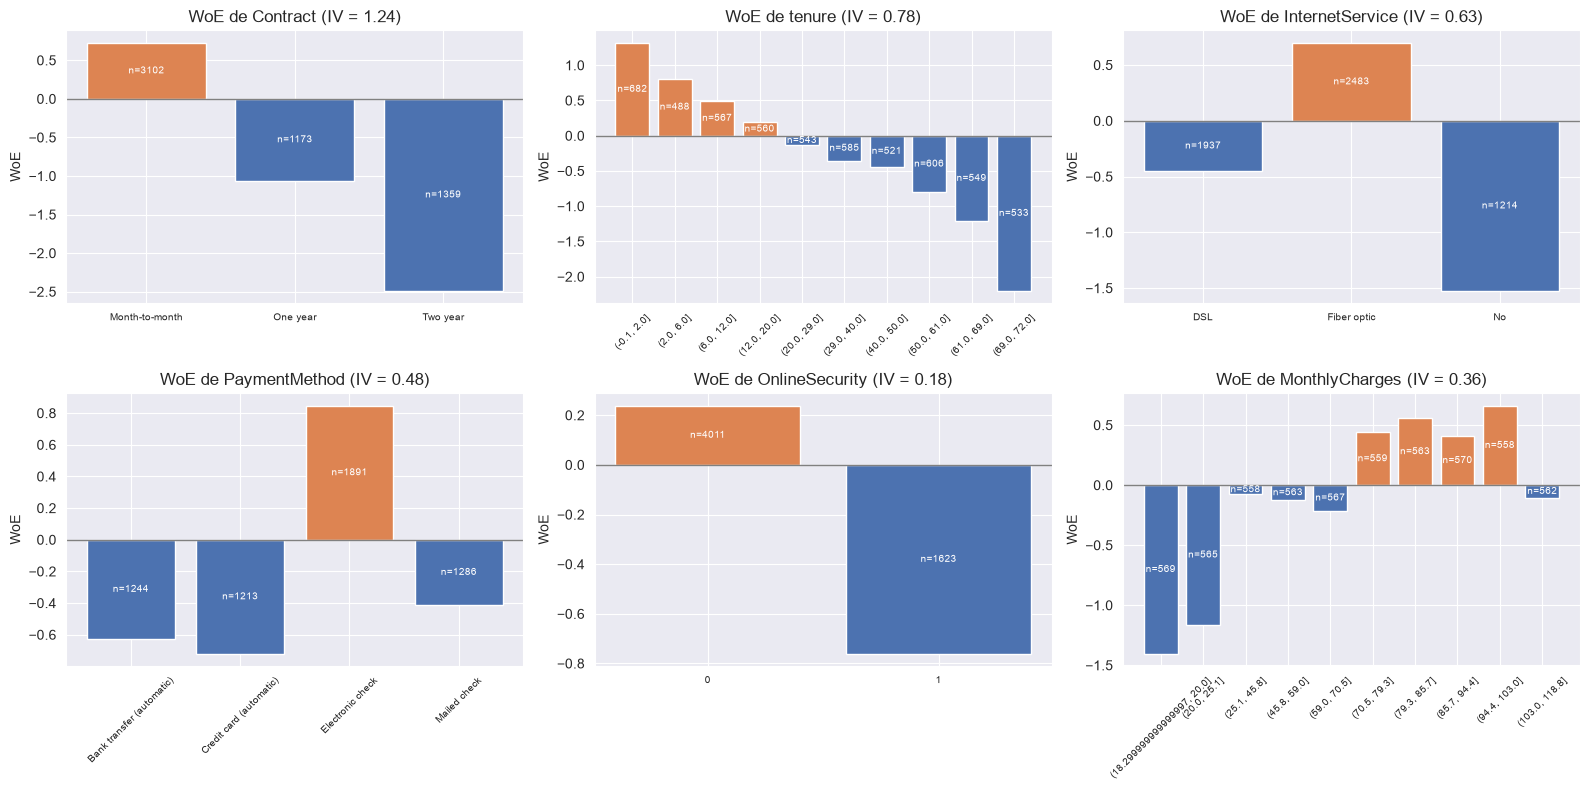

In [17]:
# WoE das categorias/faixas das variáveis mais relevantes
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for col, ax in zip(["Contract", "tenure", "InternetService", "PaymentMethod", "OnlineSecurity", "MonthlyCharges"], axes.ravel()):
    tab = tabela_woe(discretizar(X[col]), y)
    ax.bar(tab.index.astype(str), tab["woe"], color=np.where(tab["woe"] > 0, "#DD8452", "#4C72B0"))
    for xi, (woe, n) in enumerate(zip(tab["woe"], tab["n"])):
        ax.text(xi, woe / 2, f"n={n}", ha="center", va="center", fontsize=7, color="white")
    ax.axhline(0, color="gray", lw=1)
    ax.set(title=f"WoE de {col} (IV = {iv[col]:.2f})", ylabel="WoE")
    ax.tick_params(axis="x", rotation=45 if X[col].nunique() > 3 else 0, labelsize=7)
fig.tight_layout()
plt.show()

- O ranking do IV é praticamente o mesmo da informação mútua e da EDA: `Contract` (1,24), `tenure` (0,78) e `InternetService` (0,63) são "muito fortes"; `PaymentMethod` (0,48), `MonthlyCharges` (0,36) e `TotalCharges` (0,30) são "fortes".
- Em crédito, IV > 0,5 levantaria suspeita de vazamento. Aqui os valores altos são coerentes com a EDA e com o negócio (contrato e tempo de casa são conhecidos antes do cancelamento). Uma ressalva para o notebook 08: a base é um retrato, então o `tenure` de quem cancelou é o tempo até o cancelamento, e não o tempo de casa num momento anterior.
- Os gráficos de WoE mostram a **forma** de cada relação:
  - `Contract` e `tenure`: WoE cai de forma monótona (contrato mensal +0,73 → bianual −2,49; primeiros meses +1,3 → mais de 69 meses −2,2). Na escala do log-odds, a queda de `tenure` é mais rápida no início, o que justifica o `log_tenure` da seção 4.
  - `InternetService`: só a fibra tem WoE positivo; clientes sem internet têm o menor risco.
  - `PaymentMethod`: só o *Electronic check* tem WoE positivo; as outras três formas são parecidas entre si.
  - `MonthlyCharges`: relação **não monótona**. As mensalidades mais baratas (< ~US$ 25, em geral clientes sem internet) têm risco bem abaixo da média, a faixa de ~US$ 70 a ~US$ 103 fica acima, e o decil mais caro volta para perto de 0. Uma regressão logística com `MonthlyCharges` linear não consegue representar isso.
- Variáveis com IV < 0,02: `is_male` (0,000), `PhoneService` (0,002), `MultipleLines` (0,010) e `DeviceProtection` (0,0199, praticamente no limite). Streaming e `OnlineBackup` ficam logo acima, como "fracas". Parte disso vem do notebook 01: ao juntar "No internet service" com "No", a informação "não tem internet" passou para `InternetService`, e os serviços passaram a medir só a presença do serviço.

**Variáveis candidatas a remoção** (usadas no conjunto `reduzido` da seção 5), por dois critérios complementares:
- **Relevância:** IV < 0,02 (poder preditivo inútil).
- **Redundância:** `TotalCharges`, que tem IV alto, mas é quase totalmente explicada por `tenure` e `MonthlyCharges` (seção 3.2). O IV não detecta redundância, porque olha cada variável isoladamente.

In [18]:
LIMIAR_IV = 0.02
POUCO_INFORMATIVAS = iv[iv < LIMIAR_IV].index.tolist()
REDUNDANTES = ["TotalCharges"]
REMOVER = REDUNDANTES + POUCO_INFORMATIVAS
print("Pouco informativas (IV < 0,02):", POUCO_INFORMATIVAS)
print("Redundantes:                   ", REDUNDANTES)

Pouco informativas (IV < 0,02): ['DeviceProtection', 'MultipleLines', 'PhoneService', 'is_male']
Redundantes:                    ['TotalCharges']


## 4. Criação de variáveis

Com base na EDA e nas redundâncias acima, crio algumas variáveis novas. Todas são **regras fixas aplicadas linha a linha** (não estimam nenhum parâmetro a partir dos dados), então podem ser calculadas antes da divisão em folds sem vazamento de informação.

| Variável | Definição | Motivação |
|---|---|---|
| `n_servicos_adicionais` | nº de serviços adicionais de internet (0 a 6) | resume os 6 serviços; clientes com mais serviços parecem mais "presos" à empresa |
| `servicos_suporte` | `OnlineSecurity + TechSupport` (0 a 2) | na EDA, a ausência desses dois serviços foi a mais associada a churn |
| `log_tenure` | `log(1 + tenure)` | o risco cai rápido nos primeiros meses e depois estabiliza (relação não linear, difícil para a regressão logística) |
| `variacao_mensalidade` | `MonthlyCharges − TotalCharges / tenure` | mensalidade atual acima da média histórica indica aumento de preço ou upgrade recente; aproveita a informação de `TotalCharges` que não é redundante |
| `mensal_x_fibra` | contrato mensal **e** fibra óptica (0/1) | interação entre os dois grupos de maior risco da EDA |

In [19]:
def criar_variaveis(df):
    df = df.copy()
    df["n_servicos_adicionais"] = df[SERVICOS_ADICIONAIS].sum(axis=1)
    df["servicos_suporte"] = df["OnlineSecurity"] + df["TechSupport"]
    df["log_tenure"] = np.log1p(df["tenure"])
    # Para tenure = 0 ainda não há histórico: a média é a própria mensalidade (variação 0)
    cobranca_media = (df["TotalCharges"] / df["tenure"]).where(df["tenure"] > 0, df["MonthlyCharges"])
    df["variacao_mensalidade"] = df["MonthlyCharges"] - cobranca_media
    df["mensal_x_fibra"] = ((df["Contract"] == "Month-to-month")
                            & (df["InternetService"] == "Fiber optic")).astype(int)
    return df


NOVAS_NUMERICAS = ["n_servicos_adicionais", "servicos_suporte", "log_tenure", "variacao_mensalidade"]
NOVAS_BINARIAS = ["mensal_x_fibra"]

X_fe = criar_variaveis(X)
X_fe[NOVAS_NUMERICAS + NOVAS_BINARIAS].describe().round(2)

,n_servicos_adicionais,servicos_suporte,log_tenure,variacao_mensalidade,mensal_x_fibra
count,5634.00,5634.00,5634.00,5634.00,5634.00
mean,2.06,0.58,3.04,-0.01,0.30
std,1.85,0.75,1.15,2.60,0.46
min,0.00,0.00,0.00,-18.90,0.00
25%,0.00,0.00,2.30,-1.18,0.00
50%,2.00,0.00,3.40,0.00,0.00
75%,3.00,1.00,4.03,1.13,1.00
max,6.00,2.00,4.29,19.13,1.00


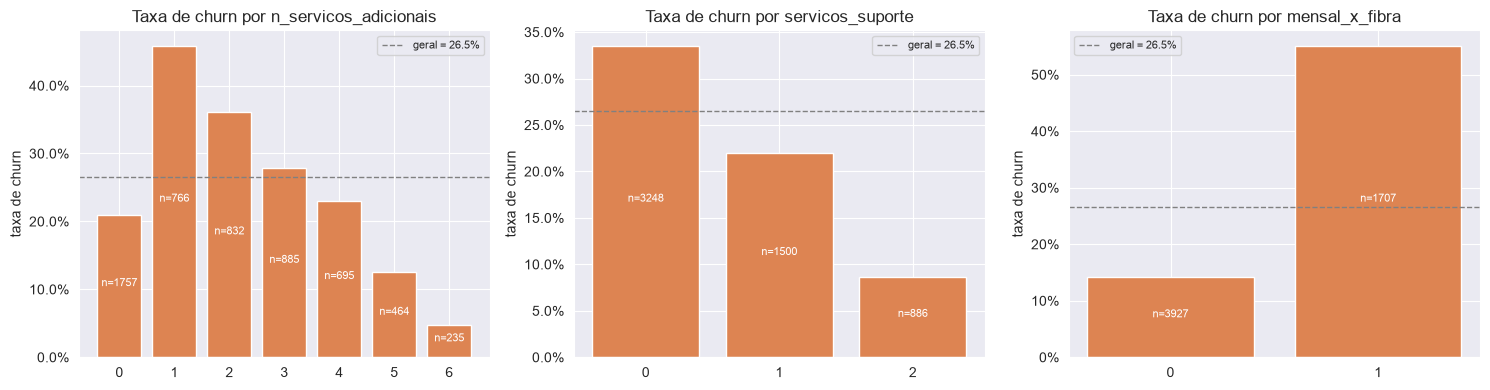

In [20]:
# Taxa de churn nas novas variáveis discretas (com o tamanho de cada grupo)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(["n_servicos_adicionais", "servicos_suporte", "mensal_x_fibra"], axes):
    tab = y.groupby(X_fe[col]).agg(n="size", taxa="mean")
    ax.bar(tab.index.astype(str), tab["taxa"], color="#DD8452")
    for xi, (taxa, n) in enumerate(zip(tab["taxa"], tab["n"])):
        ax.text(xi, taxa / 2, f"n={n}", ha="center", fontsize=8, color="white")
    ax.axhline(y.mean(), color="gray", ls="--", lw=1, label=f"geral = {y.mean():.1%}")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set(title=f"Taxa de churn por {col}", ylabel="taxa de churn")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [21]:
# variacao_mensalidade: taxa de churn por quintil
faixas = pd.qcut(X_fe["variacao_mensalidade"], q=5, duplicates="drop")
y.groupby(faixas, observed=True).agg(n="size", taxa="mean").round(3)

,n,taxa
variacao_mensalidade,,
"(-18.901, -1.531]",1127,0.308
"(-1.531, -0.3]",1127,0.165
"(-0.3, 0.276]",1126,0.369
"(0.276, 1.528]",1127,0.178
"(1.528, 19.125]",1127,0.306


In [22]:
# IV das variáveis criadas, comparado com o das originais de onde vieram
iv_novas = calcular_iv(X_fe[NOVAS_NUMERICAS + NOVAS_BINARIAS], y)
pd.DataFrame({"IV": iv_novas.round(4), "poder preditivo": pd.cut(iv_novas, FAIXAS_IV, labels=ROTULOS_IV, right=False)})

,IV,poder preditivo
mensal_x_fibra,0.8896,muito forte
log_tenure,0.7802,muito forte
n_servicos_adicionais,0.3249,forte
variacao_mensalidade,0.3162,forte
servicos_suporte,0.2745,médio


- `n_servicos_adicionais`: entre os clientes com internet, o churn cai conforme o número de serviços adicionais aumenta (45,8% com 1 serviço → 4,7% com 6). O grupo com 0 serviços tem churn baixo porque inclui os 1.214 clientes sem internet, que cancelam pouco. Essa relação não monótona é fácil para árvores, mas difícil para a regressão logística.
- `servicos_suporte`: relação clara e monótona: 33,5% → 22,0% → 8,7%.
- `mensal_x_fibra`: o grupo com contrato mensal e fibra (n = 1.707, 30% do treino) tem churn de ~55%, mais que o dobro da taxa geral.
- `variacao_mensalidade`: não tem relação monótona com o churn. Os dois extremos (mensalidade bem acima ou bem abaixo da média histórica) têm churn ~31%, e o quintil central tem o maior churn (36,9%) porque concentra os clientes novos (`tenure` 0 ou 1, em que a variação é 0 por construção). Sozinha ela é pouco informativa, então seu valor só aparece se ajudar em combinação com `tenure`.

**IV das variáveis criadas:**
- `mensal_x_fibra` tem IV 0,89: uma única variável binária com mais poder de separação que `InternetService` (0,63), perto de `Contract` (1,24). A interação concentra o risco melhor que cada variável sozinha.
- `log_tenure` tem exatamente o mesmo IV de `tenure` (0,78). Isso é esperado: o IV usa decis, que não mudam com transformações monótonas. O `log_tenure` não traz informação nova, só uma forma mais conveniente para modelos lineares.
- `n_servicos_adicionais` (0,32) e `servicos_suporte` (0,27) têm IV maior que o de qualquer serviço individual (o maior é `OnlineSecurity`, 0,18): resumir os serviços concentra a informação.
- `variacao_mensalidade` (0,32) é "forte" pelo IV, embora quase não tenha correlação linear com o churn: o IV capta a relação não monótona vista na tabela acima. Parte desse IV, porém, vem da concentração de clientes novos no quintil central, ou seja, é redundante com `tenure`.

## 5. Os conjuntos de variáveis contribuem para os resultados?

Comparo quatro conjuntos de variáveis com validação cruzada, sempre nos **mesmos 5 folds**:

- **base**: todas as 19 variáveis originais (23 colunas após o one-hot)
- **reduzido**: base sem as variáveis com IV < 0,02 (seção 3.4) e sem `TotalCharges` (redundante, seção 3.2)
- **engenharia**: base + as 5 variáveis criadas na seção 4
- **engenharia_reduzido**: engenharia sem as variáveis removidas no reduzido

Os modelos usam hiperparâmetros fixos e razoáveis: a busca de hiperparâmetros é feita no notebook 04. O objetivo aqui é só comparar os conjuntos de variáveis. A métrica principal é a **precisão média (AP)**, que resume a curva precisão–sensibilidade da classe churn e não depende de limiar. A ROC-AUC e o F1 (limiar 0,5) são mostrados como complemento.

In [23]:
def conjunto(remover=(), novas=False):
    numericas = NUMERICAS + (NOVAS_NUMERICAS if novas else [])
    binarias = BINARIAS + (NOVAS_BINARIAS if novas else [])
    return {"numericas": [c for c in numericas if c not in remover],
            "binarias": [c for c in binarias if c not in remover],
            "categoricas": CATEGORICAS}


CONJUNTOS = {
    "base": conjunto(),
    "reduzido": conjunto(REMOVER),
    "engenharia": conjunto(novas=True),
    "engenharia_reduzido": conjunto(REMOVER, novas=True),
}

MODELOS = {
    "LogReg": LogisticRegression(max_iter=5000),
    "KNN": KNeighborsClassifier(n_neighbors=25),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
    "HistGB": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, random_state=42),
}

pd.Series({nome: sum(len(v) for v in c.values()) for nome, c in CONJUNTOS.items()}, name="nº de variáveis")

base                   19
reduzido               14
engenharia             24
engenharia_reduzido    19
Name: nº de variáveis, dtype: int64

In [24]:
linhas = []
for nome_conj, c in CONJUNTOS.items():
    for nome_mod, modelo in MODELOS.items():
        pipe = Pipeline([("prep", fazer_preprocessador(**c)), ("modelo", modelo)])
        res = avaliar(pipe, X_fe, y).assign(modelo=nome_mod, configuração=nome_conj)
        linhas.append(res.rename_axis("fold").reset_index())
res_conj = pd.concat(linhas, ignore_index=True)
resumir(res_conj)

roc_auc             ap             f1
modelo       configuração                                                    
HistGB       base                 0.837 ± 0.011  0.643 ± 0.028  0.567 ± 0.025
             engenharia            0.837 ± 0.01  0.637 ± 0.032  0.577 ± 0.022
             engenharia_reduzido   0.834 ± 0.01  0.629 ± 0.024  0.564 ± 0.013
             reduzido             0.835 ± 0.011  0.642 ± 0.029  0.574 ± 0.033
KNN          base                 0.834 ± 0.011   0.62 ± 0.013  0.597 ± 0.019
             engenharia           0.836 ± 0.007  0.623 ± 0.016   0.584 ± 0.02
             engenharia_reduzido  0.833 ± 0.011  0.624 ± 0.019   0.58 ± 0.022
             reduzido              0.83 ± 0.013  0.604 ± 0.023  0.589 ± 0.023
LogReg       base                 0.846 ± 0.014  0.661 ± 0.022  0.593 ± 0.034
             engenharia           0.849 ± 0.013  0.671 ± 0.017  0.597 ± 0.032
             engenharia_reduzido  0.849 ± 0.013  0.661 ± 0.019   0.583 ± 0.03
             reduzido             0.844 ± 0.013   0.65 ± 0.022  0.593 ± 0.031
RandomForest base                 0.844 ± 0.013  0.659 ± 0.026  0.569 ± 0.022
             engenharia           0.843 ± 0.011  0.654 ± 0.026  0.572 ± 0.019
             engenharia_reduzido  0.844 ± 0.011  0.653 ± 0.029  0.573 ± 0.024
             reduzido             0.843 ± 0.012  0.654 ± 0.026   0.572 ± 0.02

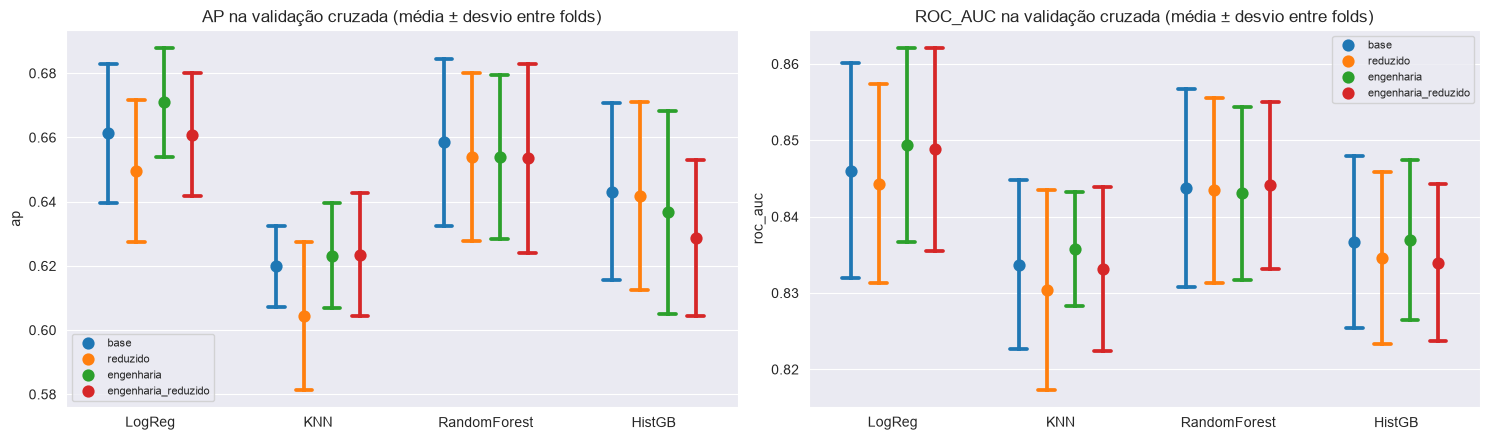

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for metrica, ax in zip(["ap", "roc_auc"], axes):
    sns.pointplot(data=res_conj, x="modelo", y=metrica, hue="configuração", errorbar="sd",
                  dodge=0.5, linestyle="none", capsize=0.1, ax=ax)
    ax.set(title=f"{metrica.upper()} na validação cruzada (média ± desvio entre folds)", xlabel="")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

O desvio entre folds é grande comparado às diferenças entre os conjuntos. Mas como todos os conjuntos usam **os mesmos folds**, dá para comparar fold a fold: calculo a diferença de AP de cada conjunto em relação ao `base` dentro de cada fold, o que elimina a variação que vem da dificuldade de cada fold.

In [26]:
ap = res_conj.pivot_table(index=["modelo", "fold"], columns="configuração", values="ap")
dif = ap.drop(columns="base").sub(ap["base"], axis=0)

pareado = pd.concat({
    "dif. média de AP": dif.groupby("modelo").mean(),
    "folds em que melhora": (dif > 0).groupby("modelo").sum(),
}, axis=1)
pareado.round(4)

dif. média de AP                               \
configuração       engenharia engenharia_reduzido reduzido   
modelo                                                       
HistGB                -0.0064             -0.0144  -0.0013   
KNN                    0.0032              0.0036  -0.0155   
LogReg                 0.0097             -0.0003  -0.0117   
RandomForest          -0.0045             -0.0050  -0.0046   

             folds em que melhora                               
configuração           engenharia engenharia_reduzido reduzido  
modelo                                                          
HistGB                          1                   1        3  
KNN                             3                   3        1  
LogReg                          4                   3        1  
RandomForest                    2                   1        1

- **Seleção por IV (`reduzido`) não ajuda:** remover as 4 variáveis com IV < 0,02 e o `TotalCharges` piora ou mantém a AP em todos os modelos (LogReg −0,012, melhor em só 1 de 5 folds; KNN −0,016; Random Forest −0,005; HistGB −0,001).
  - Uma explicação é a seção 3.2: `MonthlyCharges` é quase a soma dos preços dos serviços. Com `DeviceProtection` e `MultipleLines` no modelo, a conta mensal pode ser "decomposta" nos serviços; sem elas, parte da variação de `MonthlyCharges` fica sem explicação. **Pouca informação individual não significa pouca informação em conjunto.**
  - `DeviceProtection` saiu por ter IV 0,0199 contra um limiar de 0,02, o que mostra o quanto o corte é arbitrário.
- **Criação de variáveis (`engenharia`):** a regressão logística é o modelo que mais se beneficia. A AP sobe de 0,661 para 0,671, melhorando em 4 dos 5 folds, porque as variáveis criadas (`log_tenure`, `mensal_x_fibra`, contagens de serviços) dão ao modelo linear não linearidades e interações que ele não aprende sozinho. O KNN melhora levemente (+0,003, 3 de 5 folds).
- **Random Forest e HistGB:** com a engenharia, as diferenças são pequenas (−0,005 e −0,006, cerca de 1/4 do desvio entre folds) e sem direção consistente. As árvores já aprendem interações e cortes não lineares sozinhas.
- **`engenharia_reduzido`:** a remoção das variáveis de IV baixo cancela o ganho da engenharia na regressão logística (volta para 0,661) e é a pior configuração do HistGB (−0,014).
- Na ROC-AUC o padrão é o mesmo, com diferenças ainda menores.

De forma geral, a **criação** de variáveis ajuda um pouco os modelos que não criam interações por conta própria, e a **seleção** por IV não ajuda nenhum modelo. Os ganhos são modestos (no máximo ~1 ponto de AP); a escolha do algoritmo (notebooks 04 e 05) deve pesar mais que a escolha do conjunto de variáveis.

### 5.1 Seleção automática de variáveis

Além da seleção "manual" acima, testo uma seleção automática: manter só as $k$ colunas com maior informação mútua com o churn (`SelectKBest`). A seleção fica **dentro do pipeline**, ou seja, a informação mútua é recalculada só com o treino de cada fold.

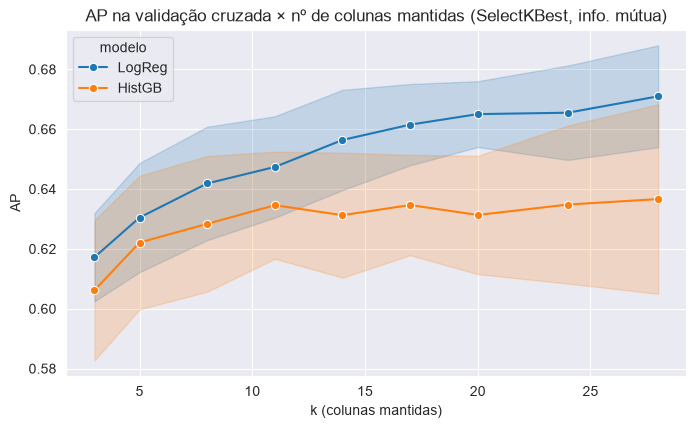

modelo,HistGB,LogReg
k,,
3,0.6062,0.6172
5,0.6221,0.6305
8,0.6284,0.6419
11,0.6346,0.6474
14,0.6313,0.6564
17,0.6346,0.6615
20,0.6313,0.6650
24,0.6348,0.6655
28,0.6366,0.6710


In [27]:
def mi(X, y):
    return mutual_info_classif(X, y, random_state=42)

c = CONJUNTOS["engenharia"]
n_colunas = fazer_preprocessador(**c).fit_transform(X_fe).shape[1]
ks = [3, 5, 8, 11, 14, 17, 20, 24, n_colunas]

linhas = []
for nome_mod in ["LogReg", "HistGB"]:
    for k in ks:
        pipe = Pipeline([("prep", fazer_preprocessador(**c)),
                         ("selecao", SelectKBest(mi, k=k)),
                         ("modelo", MODELOS[nome_mod])])
        linhas.append(avaliar(pipe, X_fe, y).assign(modelo=nome_mod, k=k))
res_k = pd.concat(linhas)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.lineplot(data=res_k, x="k", y="ap", hue="modelo", errorbar="sd", marker="o", ax=ax)
ax.set(title="AP na validação cruzada × nº de colunas mantidas (SelectKBest, info. mútua)",
       xlabel="k (colunas mantidas)", ylabel="AP")
plt.show()
res_k.groupby(["modelo", "k"])["ap"].mean().unstack(0).round(4)

A AP **aumenta com o número de colunas** nos dois modelos e é máxima usando todas elas. Manter só as colunas de maior informação mútua não melhora o resultado em nenhum valor de $k$. Isso confirma o que a seção 3.3 sugeria: variáveis com pouca informação individual ainda contribuem em conjunto, e os modelos (com regularização, no caso da logística) lidam bem com as poucas variáveis pouco úteis. Portanto, não uso seleção automática.

### 5.2 Codificação WoE × one-hot na regressão logística

O WoE também pode ser usado como **codificação**: cada categoria (ou faixa) é trocada pelo seu WoE. Para a regressão logística isso é atraente, porque o WoE já está na escala do log-odds: o modelo passa a ter uma relação linear com cada variável, mesmo quando a relação original não é monótona (ex.: decis de `MonthlyCharges`, nº de serviços).

Como o WoE usa o alvo, ele é uma forma de *target encoding* e **precisa** ser calculado só com o treino de cada fold, senão a validação cruzada fica otimista. Por isso implemento o WoE como um transformador do scikit-learn, colocado dentro do pipeline.

Comparo três codificações, nos conjuntos `base` e `engenharia`:
- **one-hot**: o pré-processamento usado até aqui
- **WoE nas categóricas**: WoE em `InternetService`, `Contract` e `PaymentMethod`; numéricas padronizadas
- **WoE em tudo**: numéricas discretizadas em decis e também codificadas por WoE (o "scorecard" clássico de crédito)

As binárias ficam em 0/1 nos três casos: para uma variável binária o WoE é só uma transformação linear de 0/1, que não muda a regressão logística.

In [28]:
class WoEEncoder(BaseEstimator, TransformerMixin):
    # Troca cada categoria pelo seu WoE. Numéricas com mais de n_faixas valores viram decis antes.
    # Os cortes dos decis e os WoE são calculados só com os dados do fit (o treino de cada fold).
    def __init__(self, n_faixas=10):
        self.n_faixas = n_faixas

    def _faixas(self, X):
        X = X.copy()
        for col, cortes in self.cortes_.items():
            X[col] = np.digitize(X[col], cortes)
        return X

    def fit(self, X, y):
        X = pd.DataFrame(X)
        quantis = np.linspace(0, 1, self.n_faixas + 1)[1:-1]
        self.cortes_ = {col: np.unique(np.quantile(X[col], quantis))
                        for col in X.select_dtypes("number") if X[col].nunique() > self.n_faixas}
        Xf, y = self._faixas(X), pd.Series(np.asarray(y), index=X.index)
        self.woe_ = {col: tabela_woe(Xf[col], y)["woe"] for col in X.columns}
        return self

    def transform(self, X):
        # Categoria que não apareceu no fit recebe WoE 0 (risco médio)
        Xf = self._faixas(pd.DataFrame(X))
        return np.column_stack([Xf[col].map(self.woe_[col]).fillna(0.0).to_numpy(float) for col in self.woe_])


def fazer_preprocessador_woe(numericas, binarias, categoricas, woe_numericas=False):
    if woe_numericas:
        return ColumnTransformer([("woe", WoEEncoder(), numericas + categoricas),
                                  ("bin", "passthrough", binarias)])
    return ColumnTransformer([("num", StandardScaler(), numericas),
                              ("bin", "passthrough", binarias),
                              ("cat", WoEEncoder(), categoricas)])


# Exemplo: WoE de Contract aprendido no treino inteiro
WoEEncoder().fit(X[["Contract"]], y).woe_["Contract"].round(3)

Contract
Month-to-month    0.726
One year         -1.061
Two year         -2.492
Name: woe, dtype: float64

In [29]:
CODIFICACOES = {
    "one-hot": lambda c: fazer_preprocessador(**c),
    "WoE nas categóricas": lambda c: fazer_preprocessador_woe(**c),
    "WoE em tudo": lambda c: fazer_preprocessador_woe(**c, woe_numericas=True),
}

linhas = []
for nome_conj in ["base", "engenharia"]:
    for nome_cod, prep in CODIFICACOES.items():
        pipe = Pipeline([("prep", prep(CONJUNTOS[nome_conj])), ("modelo", LogisticRegression(max_iter=5000))])
        res = avaliar(pipe, X_fe, y).assign(modelo=nome_conj, configuração=nome_cod)
        linhas.append(res.rename_axis("fold").reset_index())
res_woe = pd.concat(linhas, ignore_index=True)
resumir(res_woe).rename_axis(["conjunto", "codificação"])

roc_auc             ap             f1
conjunto   codificação                                                     
base       WoE em tudo          0.849 ± 0.014  0.672 ± 0.018  0.594 ± 0.036
           WoE nas categóricas  0.846 ± 0.014  0.661 ± 0.021  0.592 ± 0.033
           one-hot              0.846 ± 0.014  0.661 ± 0.022  0.593 ± 0.034
engenharia WoE em tudo          0.848 ± 0.014  0.671 ± 0.018  0.594 ± 0.039
           WoE nas categóricas   0.85 ± 0.012  0.671 ± 0.017  0.598 ± 0.033
           one-hot              0.849 ± 0.013  0.671 ± 0.017  0.597 ± 0.032

In [30]:
# Diferença de AP em relação ao one-hot, fold a fold (mesmos folds)
ap_woe = res_woe.pivot_table(index=["modelo", "fold"], columns="configuração", values="ap")
dif_woe = ap_woe.drop(columns="one-hot").sub(ap_woe["one-hot"], axis=0)
pd.concat({
    "dif. média de AP": dif_woe.groupby("modelo").mean(),
    "folds em que melhora": (dif_woe > 0).groupby("modelo").sum(),
}, axis=1).rename_axis("conjunto").round(4)

dif. média de AP                     folds em que melhora  \
configuração      WoE em tudo WoE nas categóricas          WoE em tudo   
conjunto                                                                 
base                   0.0107              0.0002                    4   
engenharia             0.0002              0.0003                    3   

                                  
configuração WoE nas categóricas  
conjunto                          
base                           2  
engenharia                     3

- **WoE nas categóricas = one-hot** (diferença ~0,000 nos dois conjuntos). Com 3 ou 4 categorias, o one-hot já dá à regressão logística um coeficiente livre por categoria; o WoE só fixa esses valores num único número. Não há ganho de informação, apenas menos colunas (3 em vez de 7).
- **WoE em tudo, no conjunto `base`: +0,011 de AP** (melhora em 4 de 5 folds), chegando a 0,672, o mesmo nível do one-hot com as variáveis criadas (0,671). O ganho vem da discretização das numéricas: com um WoE por decil, o modelo linear consegue representar a relação não monótona de `MonthlyCharges` e a queda não linear do risco com `tenure`.
- **No conjunto `engenharia`, o WoE não acrescenta nada** (+0,000). As duas abordagens capturam as mesmas não linearidades por caminhos diferentes, e os ganhos não se somam.

**Decisão:** mantenho one-hot + variáveis criadas. O desempenho é o mesmo, funciona para todos os modelos (KNN e árvores não ganham nada com WoE), as variáveis continuam diretamente interpretáveis, e não é preciso escolher faixas nem ajustar uma codificação que usa o alvo em cada fold. O "WoE em tudo" fica registrado como uma alternativa equivalente para a regressão logística (o formato clássico de *scorecard*).

## 6. Decisão e salvamento

**Conjunto escolhido: `engenharia`** (24 variáveis, 28 colunas após o one-hot)

- **Codificação:** binárias em 0/1 (notebook 01); one-hot com `drop="first"` em `InternetService`, `Contract` e `PaymentMethod`. A codificação WoE não melhorou o resultado quando as variáveis criadas estão presentes (seção 5.2).
- **Padronização:** `StandardScaler` nas numéricas (essencial para o KNN, recomendável para a regressão logística, indiferente para árvores), ajustado dentro do pipeline.
- **Removidas:** nenhuma. A remoção por IV piorou os resultados (seção 5), e a seleção automática também não ajudou (seção 5.1). `TotalCharges` continua no modelo: é redundante (seção 3.2), mas isso não prejudica a previsão. Na interpretação da regressão logística (notebook 08), os coeficientes de `tenure`, `MonthlyCharges`, `TotalCharges` e dos serviços precisam ser lidos com cuidado por causa da multicolinearidade.
- **Criadas:** `n_servicos_adicionais`, `servicos_suporte`, `log_tenure`, `variacao_mensalidade` e `mensal_x_fibra`.

**Justificativa:** é o melhor conjunto para a regressão logística (+0,010 de AP, melhor em 4 de 5 folds) e ligeiramente melhor para o KNN. Para os modelos de árvore, a diferença em relação ao `base` está dentro da variação entre folds. Usar o mesmo conjunto para todos os modelos mantém o protocolo de comparação dos notebooks 04–07 igual para todos.

**Papel do WoE/IV:** foram úteis para **interpretar** as variáveis (o ranking confirma a EDA e a informação mútua, e os gráficos de WoE mostram a forma de cada relação) e para **justificar** as variáveis criadas (que têm IV maior que as variáveis de onde vieram). Não foram úteis para **selecionar** variáveis, porque, como toda medida univariada, ignoram a informação que as variáveis carregam em conjunto.

**Ressalva:** as diferenças entre os conjuntos são pequenas e foram medidas com hiperparâmetros fixos. A conclusão principal é que a criação de variáveis ajuda pouco e principalmente o modelo linear, e a seleção não ajuda.

In [31]:
CONJUNTO_ESCOLHIDO = "engenharia"

# Variáveis escolhidas (usadas pelos próximos notebooks)
with open("../data/processed/feature_set.json", "w", encoding="utf-8") as f:
    json.dump({"conjunto": CONJUNTO_ESCOLHIDO, **CONJUNTOS[CONJUNTO_ESCOLHIDO]}, f, indent=2, ensure_ascii=False)

# Treino e teste com as variáveis criadas (regras fixas: o teste não influencia nenhuma decisão)
test = pd.read_csv("../data/processed/test.csv")
criar_variaveis(train).to_csv("../data/processed/train_fe.csv", index=False)
criar_variaveis(test).to_csv("../data/processed/test_fe.csv", index=False)

CONJUNTOS[CONJUNTO_ESCOLHIDO]

{'numericas': ['tenure',
  'MonthlyCharges',
  'TotalCharges',
  'n_servicos_adicionais',
  'servicos_suporte',
  'log_tenure',
  'variacao_mensalidade'],
 'binarias': ['is_male',
  'SeniorCitizen',
  'Partner',
  'Dependents',
  'PhoneService',
  'MultipleLines',
  'OnlineSecurity',
  'OnlineBackup',
  'DeviceProtection',
  'TechSupport',
  'StreamingTV',
  'StreamingMovies',
  'PaperlessBilling',
  'mensal_x_fibra'],
 'categoricas': ['InternetService', 'Contract', 'PaymentMethod']}

Para usar nos próximos notebooks:

```python
with open("../data/processed/feature_set.json", encoding="utf-8") as f:
    fs = json.load(f)
train = pd.read_csv("../data/processed/train_fe.csv")
X = train[fs["numericas"] + fs["binarias"] + fs["categoricas"]]
y = train["Churn"]
```
e o pré-processador é o mesmo `ColumnTransformer` da seção 1 (one-hot com `drop="first"` + `StandardScaler` nas numéricas), sempre dentro de um `Pipeline` com o modelo.